# Election fingerprints: turnout vs. vote share — Bulgarian presidential election, round 2 / runoff (1 Nov 2026)

Same methods as `turnout_fingerprint.ipynb` (round 1), applied to the **Йотова vs Гюров runoff**, plus a new section that compares every station **between the two rounds**. A runoff gives a second measurement of the same station a week later, which is a powerful extra check.

The Benford notebook asked *“do the numbers look invented?”*. This notebook asks a different question:
**do the stations with unusually high turnout also show unusually high support for one candidate?** That is the classic signature
of **ballot stuffing** and **controlled/bought votes**, which digit tests can't see.

## The methods
| Method | Idea | Reference |
|---|---|---|
| **Election fingerprint** | 2-D histogram of turnout × candidate share per station. Honest elections give one compact blob. Stuffing smears it toward the top-right; “extreme” fraud makes a cluster near 100% turnout / 100% share. | Klimek, Yegorov, Hanel & Thurner, *PNAS* 2012 |
| **Turnout-binned votes** | How a candidate's votes and share change as turnout rises. Stuffing adds a long high-turnout tail for one candidate only. | Shpilkin (Russia 2011–), Kobak et al. 2016 |
| **Integer-percentage test** | Fabricated results are often written to hit round percentages (e.g. turnout exactly 80%). Look for an excess of integer percentages. | Kobak, Shpilkin & Pshenichnikov, *Significance* 2016 |
| **Fraud injection** | Add synthetic fraud to the real data to see what it *would* look like, i.e. how much fraud these methods could detect. | — |

## The big caveat
Turnout and vote share can be correlated for innocent reasons: cities vs. villages, age, education, ethnicity. A
candidate who is strong where people vote more will show a “suspicious” slope. So every pattern below also gets checked
**within the same municipality / same building**, where demographics are much more similar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from load_data import load_votes, load_sections, ROUND1, ROUND2

votes = load_votes(election=ROUND2)
meta = load_sections(ROUND2)

NONE = "Не подкрепям никого"
cand_cols = [c for c in votes.columns if c != NONE]
ranked = list(votes[cand_cols].sum().sort_values(ascending=False).index)
TOP = ranked[:2]        # the two runoff candidates
short = lambda c: c.split(" ", 1)[1] if c[:2].isdigit() else c

df = meta.join(votes)
df["registered"] = df["voters_list"] + df["voters_added"]
df["voted"] = df["voted_signatures"]
df["turnout"] = df["voted"] / df["registered"]
df["valid"] = votes.sum(axis=1)
for c in votes.columns:
    df[f"share|{c}"] = df[c] / df["valid"]
print(df.shape)

(12717, 27)


In [2]:
# ---- chart style ----
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SERIES = [BLUE, ORANGE, AQUA, YELLOW]          # fixed categorical order, follows candidate rank
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110, "legend.frameon": False,
})
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
def suptitle(fig, s): fig.suptitle(s, x=0.01, ha="left", fontsize=13, fontweight="bold")

## 1. Which polling stations can be used
Turnout = voters who signed ÷ (voters on the list + voters added on election day). It only means something where the voter
list is meaningful:
* **Abroad**: there are no pre-made lists (almost everyone is “added”), so turnout is ~100% by construction. Excluded.
* **Mobile boxes, ships**: excluded.
* **Very small stations (< 100 registered)**: mostly hospitals, care homes and prisons with special lists. Excluded.
* **Stations where more than half of the voters were added on the day**: special sections. Excluded.

In [3]:
rules = {
    "abroad": df["abroad"],
    "mobile / ship": (df["mobile"] == 1) | (df["ship"] == 1),
    "< 100 registered": df["registered"] < 100,
    "> 50% added on the day": df["voters_added"] / df["registered"] > 0.5,
}
excluded = pd.Series(False, index=df.index)
rows = {}
for name, mask in rules.items():
    rows[name] = (mask & ~excluded).sum()
    excluded |= mask
base = df[~excluded].copy()
rows["→ stations kept"] = len(base)
pd.Series(rows, name="stations").to_frame()

,stations
abroad,613
mobile / ship,263
< 100 registered,1172
> 50% added on the day,16
→ stations kept,10653


## 2. Turnout distribution

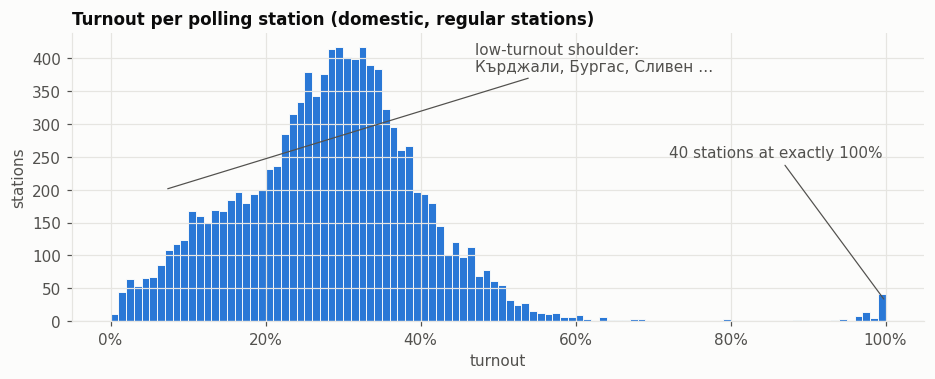

median turnout: 28.8%


In [4]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(base["turnout"], bins=np.arange(0, 1.005, 0.01), color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.set_xlabel("turnout"); ax.set_ylabel("stations"); ax.xaxis.set_major_formatter(pct)
ax.set_title("Turnout per polling station (domestic, regular stations)")
n100 = (base["voted"] >= base["registered"]).sum()
ax.annotate(f"{n100} stations at exactly 100%", xy=(1, 30), xytext=(0.72, 250), color=INK2,
            arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
low = base[base["turnout"] < 0.12]["admin_name"].value_counts().head(3)
ax.annotate("low-turnout shoulder:\n" + ", ".join(i.split(". ")[1].title() for i in low.index) + " …",
            xy=(0.07, 200), xytext=(0.47, 380), color=INK2, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
plt.show()
print(f"median turnout: {base['turnout'].median():.1%}")

Two features stand out:
* **A low-turnout shoulder (5–12%)**, mostly Кърджали and other regions with a large ethnic-Turkish population and heavy emigration to
  Turkey (emigrants remain on the lists). This is a known demographic effect, not fraud.
* **A spike at exactly 100%.** This is exactly where Klimek's “extreme fraud” would show up, so it needs a closer look.

## 3. The 100%-turnout stations: fraud or paperwork?
If these were stuffed, we would expect (a) a normal-sized voter list with far more voters than the neighbours and (b) one
candidate with an extreme share. We compare each one with the **other polling stations in the same building**, whose voters
come from the same neighbourhood.

In [5]:
def same_address_neighbours(row):
    nb = df[(df["address"] == row["address"]) & (df.index != row.name) & ~df["abroad"] & (df["mobile"] == 0)]
    return pd.Series({
        "neighbours": len(nb),
        "neighbours' median list": nb["voters_list"].median() if len(nb) else np.nan,
        "neighbours' median voted": nb["voted"].median() if len(nb) else np.nan,
        "neighbours' median turnout": nb["turnout"].median() if len(nb) else np.nan,
    })

full = base[base["turnout"] >= 0.95].copy()
full["top candidate"] = full[[f"share|{c}" for c in cand_cols]].idxmax(axis=1).str.replace("share|", "", regex=False).map(short)
full["top share"] = full[[f"share|{c}" for c in cand_cols]].max(axis=1)
full = full.join(full.apply(same_address_neighbours, axis=1))
cols = ["place", "voters_list", "voters_added", "voted", "turnout", "top candidate", "top share",
        "neighbours", "neighbours' median list", "neighbours' median voted", "neighbours' median turnout"]
full[cols].sort_values("neighbours' median list", ascending=False).style.format({
    "turnout": "{:.0%}", "top share": "{:.0%}", "neighbours' median turnout": "{:.0%}",
    "neighbours' median list": "{:.0f}", "neighbours' median voted": "{:.0f}", "neighbours": "{:.0f}"})

,place,voters_list,voters_added,voted,turnout,top candidate,top share,neighbours,neighbours' median list,neighbours' median voted,neighbours' median turnout
section,,,,,,,,,,,
211100030,с.Ябланово,111,3,114,100%,Илияна Йотова,64%,3,978,113,12%
013300022,гр.Петрич,230,8,230,97%,Илияна Йотова,80%,3,977,126,13%
082800006,гр.Добрич,265,7,265,97%,Илияна Йотова,62%,2,948,319,33%
173300008,гр.Съединение,153,0,153,100%,Илияна Йотова,62%,1,908,86,9%
254619100,гр.София,319,7,319,98%,Илияна Йотова,50%,7,903,319,34%
131900153,с.Алеко Константиново,111,5,116,100%,Илияна Йотова,73%,1,843,39,5%
182600031,гр.Разград,211,6,211,97%,Илияна Йотова,63%,1,822,231,28%
152400031,гр.Плевен,176,6,176,97%,Илияна Йотова,73%,10,812,188,22%
234615106,гр.София,211,7,218,100%,Андрей Гюров,49%,25,795,317,39%


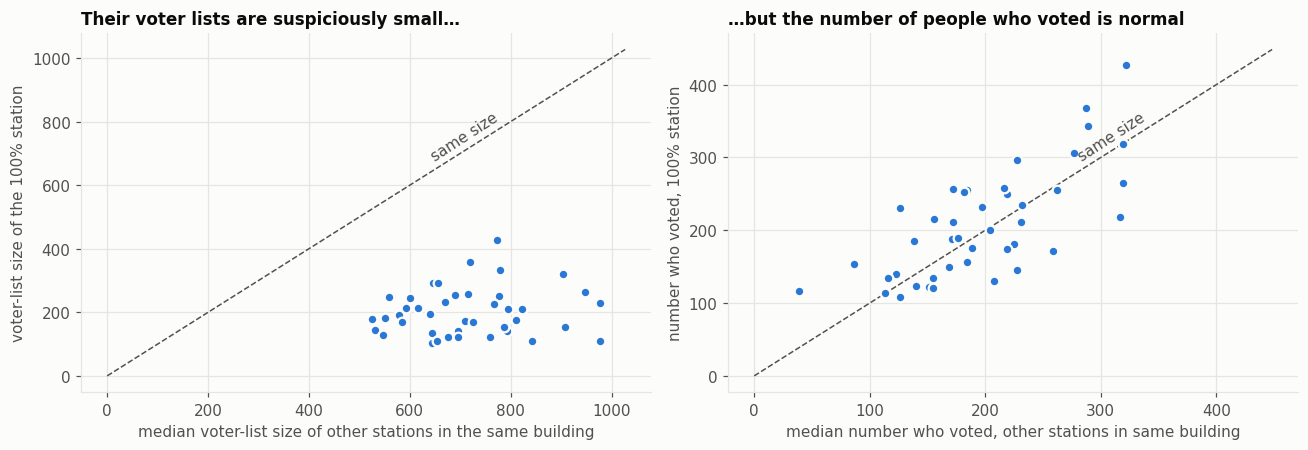

70 stations with turnout ≥ 95%; 42 share a building with other stations.
Median top-candidate share in these stations: 67% (nationwide median of the top candidate per station: 66%)


In [6]:
has_nb = full.dropna(subset=["neighbours' median list"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.scatter(has_nb["neighbours' median list"], has_nb["voters_list"], s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
m = max(has_nb["neighbours' median list"].max(), has_nb["voters_list"].max()) * 1.05
ax.plot([0, m], [0, m], color=INK2, lw=1, ls="--"); ax.text(m * 0.62, m * 0.66, "same size", color=INK2, rotation=33)
ax.set_xlabel("median voter-list size of other stations in the same building"); ax.set_ylabel("voter-list size of the 100% station")
ax.set_title("Their voter lists are suspiciously small…")
ax = axes[1]
ax.scatter(has_nb["neighbours' median voted"], has_nb["voted"], s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
m = max(has_nb["neighbours' median voted"].max(), has_nb["voted"].max()) * 1.05
ax.plot([0, m], [0, m], color=INK2, lw=1, ls="--"); ax.text(m * 0.62, m * 0.66, "same size", color=INK2, rotation=33)
ax.set_xlabel("median number who voted, other stations in same building"); ax.set_ylabel("number who voted, 100% station")
ax.set_title("…but the number of people who voted is normal")
fig.tight_layout(); plt.show()

print(f"{len(full)} stations with turnout ≥ 95%; {len(has_nb)} share a building with other stations.")
print(f"Median top-candidate share in these stations: {full['top share'].median():.0%} "
      f"(nationwide median of the top candidate per station: {base[[f'share|{c}' for c in cand_cols]].max(axis=1).median():.0%})")

**Verdict on the 100% spike:** the number of people who voted, and how they voted, look just like the neighbouring stations.
Only the **voter-list size** is wrong: it is 3–5× smaller than in the stations next door and almost equal to the number who
voted. The most likely explanation is a **protocol filling error**: the committee wrote (roughly) the number of voters who
signed into the “voters on the list” field. Ballot stuffing would inflate the *votes*, not shrink the *list*.

That is a data-quality issue worth reporting (the scanned protocols on the CIK results site would confirm it), but it is not a
fraud signal. We **exclude** these stations from the fingerprint so they don't create a fake “100% turnout” cluster.

In [7]:
suspect_list = full.index[full["voters_list"] < 0.6 * full["neighbours' median list"]]
clean = base.drop(index=suspect_list)
print(f"excluded {len(suspect_list)} stations with an implausibly small voter list → {len(clean)} stations remain")

excluded 42 stations with an implausibly small voter list → 10611 stations remain


## 4. The election fingerprint
Each panel is a 2-D histogram: x = station turnout, y = candidate's share in that station, colour = number of stations
(log scale). The grey markers show where the two fraud signatures would appear.

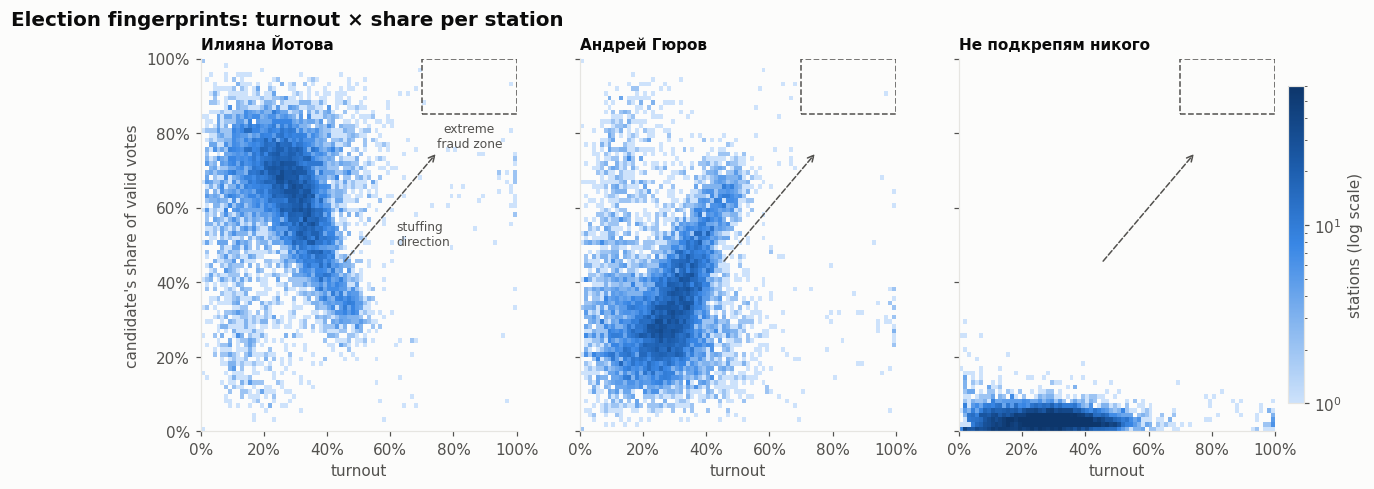

In [8]:
def fingerprint(ax, data, cand, title=None, bins=80, vmax=None):
    h = ax.hist2d(data["turnout"], data[f"share|{cand}"], bins=bins, range=[[0, 1], [0, 1]],
                  cmap=SEQ, norm=LogNorm(vmin=1, vmax=vmax), cmin=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(False)
    ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
    ax.set_title(title or short(cand), fontsize=10)
    return h

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, c in zip(axes, TOP + [NONE]):
    h = fingerprint(ax, clean, c, vmax=60)
    ax.set_xlabel("turnout")
    ax.add_patch(plt.Rectangle((0.7, 0.85), 0.3, 0.15, fill=False, ec=INK2, ls="--", lw=1))
    ax.annotate("", xy=(0.75, 0.75), xytext=(0.45, 0.45), arrowprops=dict(arrowstyle="->", color=INK2, lw=1, ls="--"))
axes[0].set_ylabel("candidate's share of valid votes")
axes[0].text(0.85, 0.83, "extreme\nfraud zone", ha="center", va="top", fontsize=8, color=INK2)
axes[0].text(0.62, 0.5, "stuffing\ndirection", fontsize=8, color=INK2)
fig.colorbar(h[3], ax=axes, shrink=0.85, label="stations (log scale)", pad=0.01)
suptitle(fig, "Election fingerprints: turnout × share per station")
plt.show()

**What to look for:** an honest election gives one compact blob. Ballot stuffing for candidate X would pull a **comet tail from
the blob toward the top-right** of X's panel, and a cluster inside the dashed box.

In a two-candidate race the two panels are near mirror images (Йотова ≈ 100% − Гюров − “none”). The extreme-fraud box is drawn at
**turnout > 70% and share > 85%**, since 70% shares are ordinary in a runoff (Йотова's 95th percentile is about 83%). Section 5 checks
whether any slope is fraud or demography.

## 5. Is the slope fraud or demography?
If one candidate's slope came from stuffing, it would persist when we compare **stations in the same municipality** or, even
stricter, **stations in the same building** (same neighbourhood, same committee pool). If it is demography (cities vs.
villages, wealthy vs. poor districts), it should shrink a lot once we compare like with like.

In [9]:
def within_corr(data, cand, group):
    t = data["turnout"] - data.groupby(group)["turnout"].transform("mean")
    s = data[f"share|{cand}"] - data.groupby(group)[f"share|{cand}"].transform("mean")
    ok = data.groupby(group)["turnout"].transform("size") >= 2
    return np.corrcoef(t[ok], s[ok])[0, 1]

corr = pd.DataFrame({
    short(c): {
        "raw (whole country)": np.corrcoef(clean["turnout"], clean[f"share|{c}"])[0, 1],
        "within region": within_corr(clean, c, "region"),
        "within municipality": within_corr(clean, c, "municipality"),
        "within same building": within_corr(clean, c, "address"),
    } for c in TOP + [NONE]
}).T
corr.style.format("{:+.2f}").background_gradient(cmap=LinearSegmentedColormap.from_list("d", ["#2a78d6", "#f0efec", "#e34948"]),
                                                vmin=-0.5, vmax=0.5)

,raw (whole country),within region,within municipality,within same building
Илияна Йотова,-0.17,-0.10,-0.12,-0.08
Андрей Гюров,+0.18,+0.10,+0.14,+0.10
Не подкрепям никого,-0.05,-0.05,-0.06,-0.06


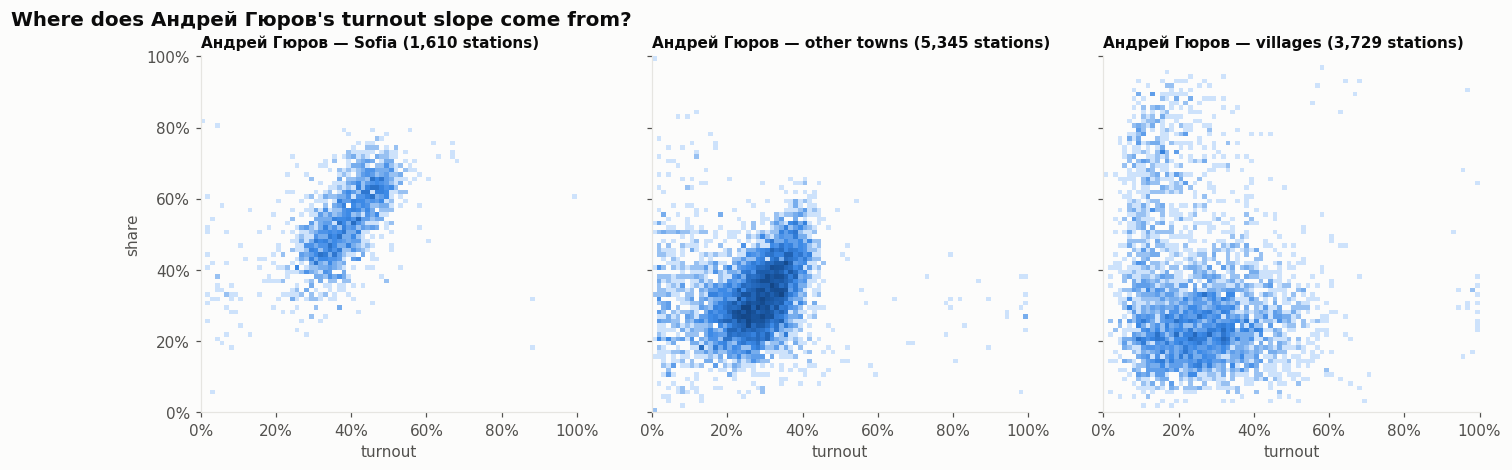

,stations,median_turnout,median share Илияна Йотова,median share Андрей Гюров
type,,,,
Sofia,1610,39%,43%,54%
other towns,5345,28%,65%,32%
villages,3656,23%,70%,26%


In [10]:
# Demography check: Гюров's share vs turnout, cities vs villages
g = ranked[1]
is_city = clean["place"].str.lower().str.startswith("гр.")
sofia = clean["region"].isin([23, 24, 25])
groups = {"Sofia": sofia, "other towns": is_city & ~sofia, "villages": ~is_city}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (name, mask) in zip(axes, groups.items()):
    h = fingerprint(ax, clean[mask], g, title=f"{short(g)} — {name} ({mask.sum():,} stations)", vmax=40)
    ax.set_xlabel("turnout")
axes[0].set_ylabel("share")
suptitle(fig, f"Where does {short(g)}'s turnout slope come from?")
plt.show()
clean.assign(type=np.select([sofia, is_city], ["Sofia", "other towns"], "villages")).groupby("type").agg(
    stations=("turnout", "size"), median_turnout=("turnout", "median"),
    **{f"median share {short(c)}": (f"share|{c}", "median") for c in TOP[:2]}).style.format(
    {"median_turnout": "{:.0%}", **{f"median share {short(c)}": "{:.0%}" for c in TOP[:2]}})

## 6. Votes by turnout level (Shpilkin's method)
Sort all stations by turnout and add up each candidate's votes per 1-percentage-point turnout bin.
* In a clean election every candidate's curve has roughly the **same bell shape**, and shares stay roughly flat.
* Stuffing creates a **second hump or long right tail** for the beneficiary only, with that candidate's share climbing toward the high-turnout end.

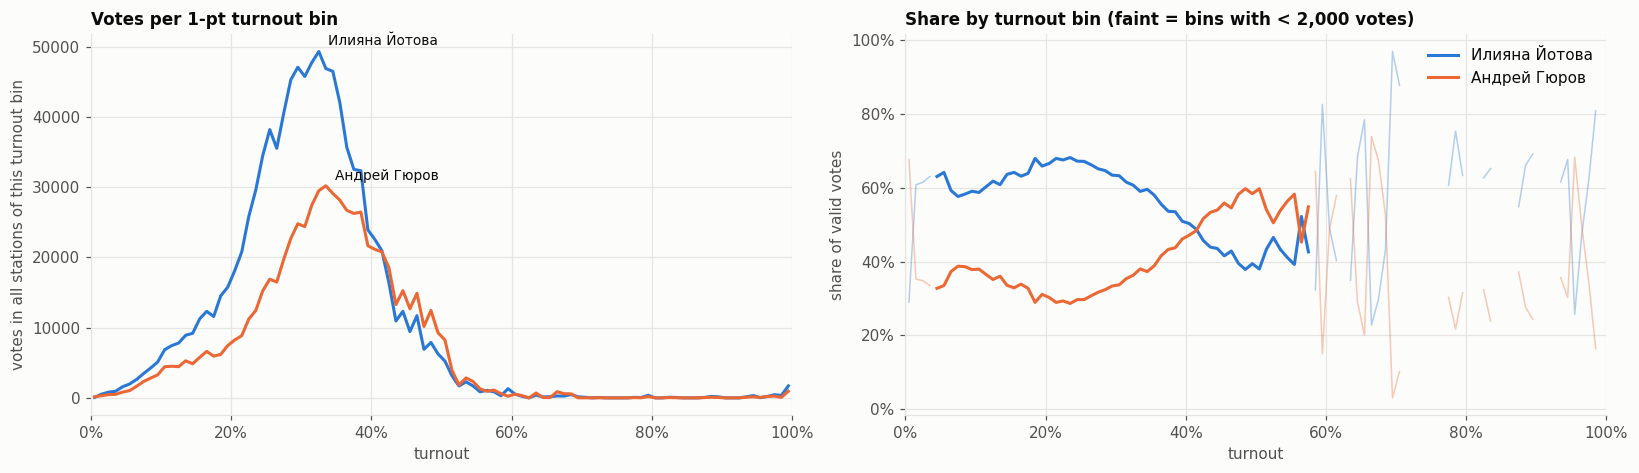

In [11]:
bins = np.arange(0, 1.0001, 0.01)
clean["tbin"] = pd.cut(clean["turnout"], bins, labels=bins[:-1] + 0.005)
by_bin = clean.groupby("tbin", observed=False)[TOP + ["valid"]].sum()
x = by_bin.index.astype(float).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
ax = axes[0]
for c, col in zip(TOP, SERIES):
    ax.plot(x, by_bin[c], color=col, lw=2, label=short(c))
ax.set_xlabel("turnout"); ax.set_ylabel("votes in all stations of this turnout bin"); ax.xaxis.set_major_formatter(pct)
ax.set_title("Votes per 1-pt turnout bin"); ax.set_xlim(0, 1)
for c, col in zip(TOP, SERIES):
    i = by_bin[c].values.argmax(); ax.annotate(short(c), (x[i], by_bin[c].iloc[i]), xytext=(6, 4), textcoords="offset points", color=INK, fontsize=9)

ax = axes[1]
share = by_bin[TOP].div(by_bin["valid"], axis=0)
enough = (by_bin["valid"] >= 2000).to_numpy()
for c, col in zip(TOP, SERIES):
    y = share[c].to_numpy()
    ax.plot(x, np.where(enough, y, np.nan), color=col, lw=2, label=short(c))
    ax.plot(x, np.where(enough, np.nan, y), color=col, lw=1, alpha=0.35)
ax.set_xlabel("turnout"); ax.set_ylabel("share of valid votes"); ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_title("Share by turnout bin (faint = bins with < 2,000 votes)"); ax.set_xlim(0, 1)
ax.legend(loc="upper right")
fig.tight_layout(); plt.show()

**Within-municipality version.** Same idea, but turnout is measured **relative to the municipality's median**. This removes the
city-vs-village effect: a station at +20 pts is one where far more people voted than in comparable stations nearby.

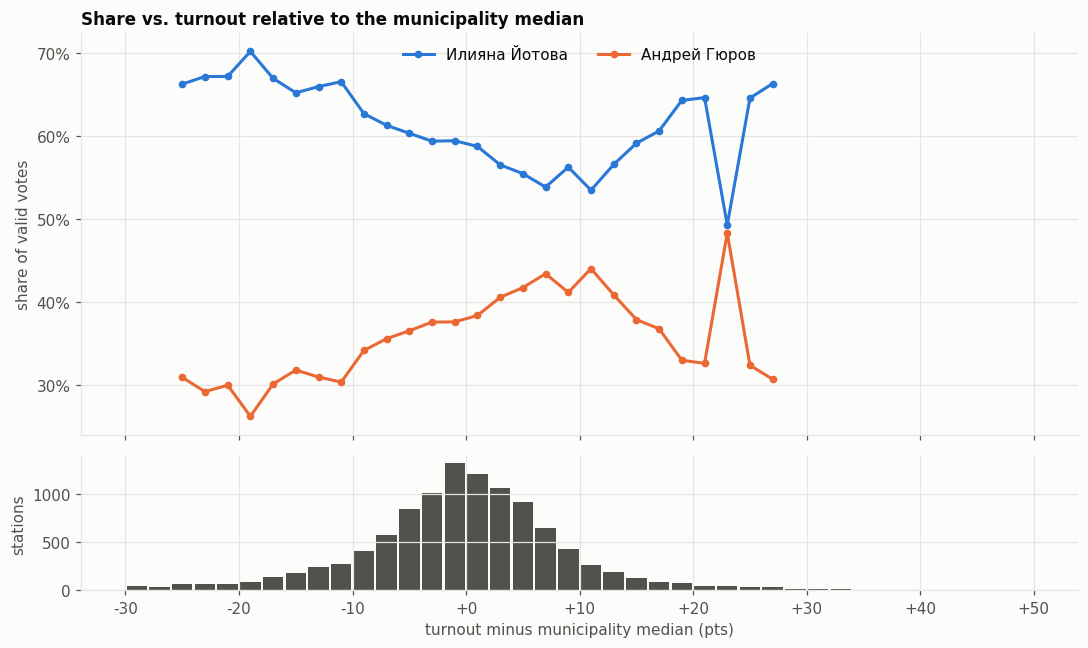

In [12]:
clean["t_rel"] = clean["turnout"] - clean.groupby("municipality")["turnout"].transform("median")
rbins = np.arange(-0.3, 0.51, 0.02)
clean["rbin"] = pd.cut(clean["t_rel"], rbins, labels=rbins[:-1] + 0.01)
rb = clean.groupby("rbin", observed=False)[TOP + ["valid"]].sum()
rshare = rb[TOP].div(rb["valid"], axis=0); xr = rb.index.astype(float).to_numpy(); ok = (rb["valid"] >= 2000).to_numpy()
nstat = clean.groupby("rbin", observed=False).size()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax = axes[0]
for c, col in zip(TOP, SERIES):
    ax.plot(xr[ok], rshare[c].to_numpy()[ok], color=col, lw=2, marker="o", ms=4, label=short(c))
ax.yaxis.set_major_formatter(pct); ax.set_ylabel("share of valid votes")
ax.legend(ncol=4, loc="upper center"); ax.set_title("Share vs. turnout relative to the municipality median")
axes[1].bar(xr, nstat, width=0.018, color=INK2)
axes[1].set_ylabel("stations"); axes[1].set_xlabel("turnout minus municipality median (pts)")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v*100:+.0f}"))
fig.tight_layout(); plt.show()

## 7. What would fraud look like here? (fraud injection)
To calibrate our eyes, and to estimate how much fraud these plots could catch, we take the **real data** and inject
synthetic fraud in favour of the leading candidate (Йотова), following Klimek's model:
* **Incremental fraud** in 5% of stations: a random 10–40% of the people who *didn't* vote are added as ballots for her.
* **Extreme fraud** in 1% of stations: 85–100% of non-voters are added for her and 80% of other candidates' votes are switched to her.

If such fraud had happened, the fingerprint would look like the middle and right panels.

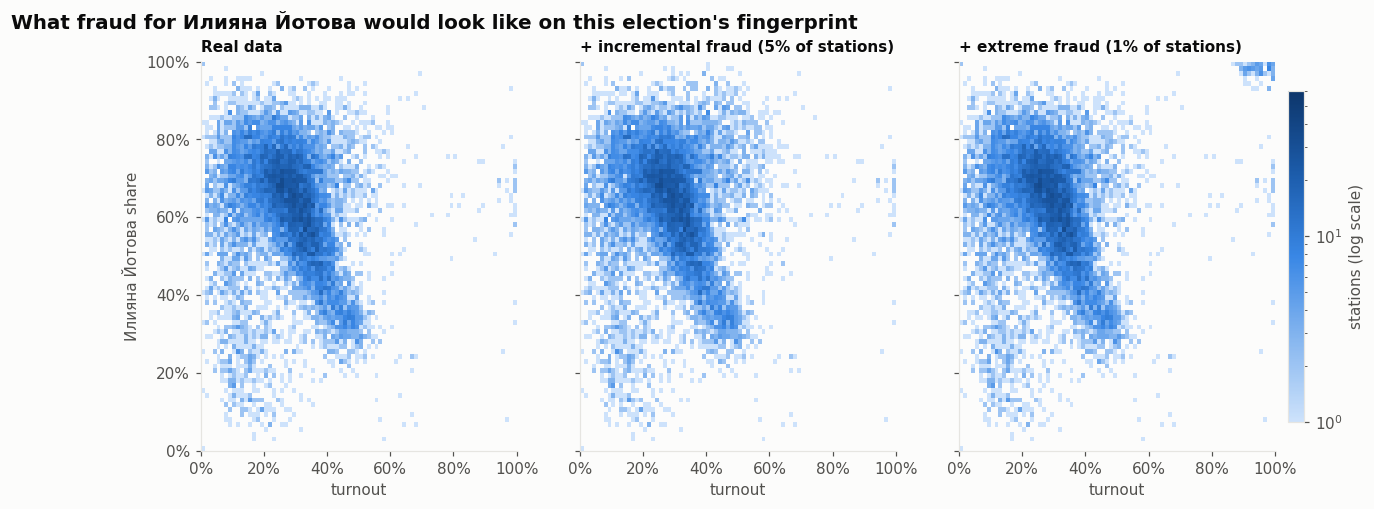

,stations with turnout > 70% and Илияна Йотова > 85%
Real data,2
+ incremental fraud (5% of stations),3
+ extreme fraud (1% of stations),108


In [13]:
rng = np.random.default_rng(7)
W = ranked[0]

def inject(data, cand, frac_stations, stuff_lo, stuff_hi, switch=0.0):
    d = data.copy()
    idx = rng.choice(len(d), int(frac_stations * len(d)), replace=False)
    sub = d.iloc[idx]
    stuffed = np.round((sub["registered"] - sub["voted"]) * rng.uniform(stuff_lo, stuff_hi, len(sub)))
    others = sub["valid"] - sub[cand]
    switched = np.round(others * switch)
    others_cols = [c for c in votes.columns if c != cand]
    keep = 1 - switch
    d.loc[sub.index, others_cols] = np.round(sub[others_cols].mul(keep)).to_numpy()
    d.loc[sub.index, cand] = sub[cand] + stuffed + switched
    d.loc[sub.index, "valid"] = d.loc[sub.index, list(votes.columns)].sum(axis=1)
    d.loc[sub.index, "voted"] = sub["voted"] + stuffed
    d.loc[sub.index, "turnout"] = d.loc[sub.index, "voted"] / sub["registered"]
    for c in votes.columns:
        d.loc[sub.index, f"share|{c}"] = d.loc[sub.index, c] / d.loc[sub.index, "valid"]
    return d

scenarios = {
    "Real data": clean,
    "+ incremental fraud (5% of stations)": inject(clean, W, 0.05, 0.10, 0.40),
    "+ extreme fraud (1% of stations)": inject(clean, W, 0.01, 0.85, 1.0, switch=0.8),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, (name, d) in zip(axes, scenarios.items()):
    h = fingerprint(ax, d, W, title=name, vmax=60); ax.set_xlabel("turnout")
axes[0].set_ylabel(f"{short(W)} share")
fig.colorbar(h[3], ax=axes, shrink=0.85, label="stations (log scale)", pad=0.01)
suptitle(fig, f"What fraud for {short(W)} would look like on this election's fingerprint")
plt.show()

def corner(d, cand, t=0.7, s=0.85):
    return int(((d["turnout"] > t) & (d[f"share|{cand}"] > s)).sum())
pd.DataFrame({name: {f"stations with turnout > 70% and {short(W)} > 85%": corner(d, W)} for name, d in scenarios.items()}).T

## 8. Who gets the extra voters?
Correlation only says turnout and share move together. A sharper question: **when turnout in a station is higher than in
comparable stations, how are the extra ballots split?**

We regress each candidate's votes per registered voter on turnout, comparing stations **within the same municipality** and
**within the same building**. The slope is the share of each additional ballot that goes to the candidate.
* **Honest variation:** extra voters split roughly like everyone else, so slope ≈ the candidate's overall share (ratio ≈ 1).
* **Ballot stuffing for X:** almost every extra ballot goes to X, so X's slope → 1 (ratio → 1 / share, ≈ 1.7 for Йотова), and the
  others' ratios drop. In a two-candidate race the ratios are linked: if one
  candidate is above 1, the other must be below.

The last block re-runs the test on the data with the **injected incremental fraud** from section 7, to show what a positive
result looks like.

In [14]:
SLOPE_COLS = TOP + [NONE]

def extra_voter_slopes(data, group):
    t = data["turnout"] - data.groupby(group)["turnout"].transform("mean")
    out = {}
    for c in SLOPE_COLS:
        y = data[c] / data["registered"]
        y = y - y.groupby(data[group]).transform("mean")
        out[c] = (t * y).sum() / (t * t).sum()
    return pd.Series(out)

overall_share = clean[SLOPE_COLS].sum() / clean["valid"].sum()
blocks = {}
for label, data in [("real", clean), ("with injected fraud for " + short(W), scenarios["+ incremental fraud (5% of stations)"])]:
    for g, gname in [("municipality", "within municipality"), ("address", "within building")]:
        if label != "real" and g == "address":
            continue
        sl = extra_voter_slopes(data, g)
        blocks[(label, gname, "slope")] = sl
        blocks[(label, gname, "ratio to share")] = sl / overall_share
slope_tab = pd.DataFrame(blocks)
slope_tab.insert(0, "overall share", overall_share)
slope_tab.index = [short(c) for c in slope_tab.index]
slope_tab.style.format("{:.2f}").format("{:.1%}", subset=["overall share"])

## 9. The extreme corner for every candidate
Stations with **turnout > 70% and one candidate > 85%**: the zone where extreme fraud would land. In an honest election a handful
of such stations can occur (e.g. small, very homogeneous villages). Here they are, for inspection.

In [15]:
rows = []
for c in cand_cols:
    m = (clean["turnout"] > 0.7) & (clean[f"share|{c}"] > 0.85)
    for s, r in clean[m].iterrows():
        rows.append({"section": s, "candidate": short(c), "place": r["place"], "address": r["address"][:60],
                     "registered": r["registered"], "voted": r["voted"], "turnout": r["turnout"], "share": r[f"share|{c}"],
                     "municipality median turnout": clean.loc[clean["municipality"] == r["municipality"], "turnout"].median()})
corner_tab = pd.DataFrame(rows)
print(f"{len(corner_tab)} stations in the extreme corner (out of {len(clean):,})")
corner_tab.style.format({"turnout": "{:.0%}", "share": "{:.0%}", "municipality median turnout": "{:.0%}"}) if len(corner_tab) else None

3 stations in the extreme corner (out of 10,611)


,section,candidate,place,address,registered,voted,turnout,share,municipality median turnout
0,301100009,Андрей Гюров,с.Живково,"С.ЖИВКОВО, Зала ул. Тополите №22",168,162,96%,90%,19%
1,042600015,Илияна Йотова,с.Градина,"С.ГРАДИНА, Общинска сграда, столова на Градина 2007 ЕООД,",141,99,70%,88%,24%
2,200100202,Илияна Йотова,гр.Алфатар,"ГР.АЛФАТАР, НЧ Йордан Йовков-1894 г. ул. Йордан Петров №1",174,171,98%,93%,32%


## 10. The reverse pattern: very low turnout, very high share
In round 1 this was where the one persistent pattern showed up: small blocs voting for Василев in neighbourhoods where almost nobody
else voted. In a runoff, “one candidate > 50%” is true everywhere, so the bar is **turnout < 12% and one candidate > 85%**.
We then keep only the stations that are low-turnout **for their own municipality** (< 40% of the municipal median). That separates
station-level anomalies from regions where everyone abstained.

In [16]:
LOW_T, HIGH_S = 0.12, 0.85
muni_t = clean.groupby("municipality")["turnout"].median()
clean["municipality median turnout"] = clean["municipality"].map(muni_t)
cnt = {}
for c in TOP:
    m = (clean["turnout"] < LOW_T) & (clean[f"share|{c}"] > HIGH_S)
    loc = m & (clean["turnout"] < 0.4 * clean["municipality median turnout"])
    sub = clean[m]
    cnt[short(c)] = {"stations": int(m.sum()), "…of which locally anomalous": int(loc.sum()),
                     "votes for candidate there": int(sub[c].sum()),
                     "% of candidate's national votes": sub[c].sum() / clean[c].sum(),
                     "% in towns (гр.)": sub["place"].str.startswith("гр.").mean() if len(sub) else np.nan,
                     "top regions": ", ".join(f"{r.split('. ')[1].title()} ({n})" for r, n in sub["admin_name"].value_counts().head(4).items())}
pd.DataFrame(cnt).T.style.format({"% of candidate's national votes": "{:.1%}", "% in towns (гр.)": "{:.0%}"})

,stations,…of which locally anomalous,votes for candidate there,% of candidate's national votes,% in towns (гр.),top regions
Илияна Йотова,62,37,2969,0.3%,55%,"Хасково (7), Сливен (6), Варна (6), Стара Загора (4)"
Андрей Гюров,12,1,549,0.1%,8%,"Кърджали (11), Сливен (1)"


In [17]:
loc_rows = []
for c in TOP:
    m = (clean["turnout"] < LOW_T) & (clean[f"share|{c}"] > HIGH_S) & (clean["turnout"] < 0.4 * clean["municipality median turnout"])
    for sec, r in clean[m].iterrows():
        bld = clean.loc[(clean["address"] == r["address"]) & (clean.index != sec), "turnout"]
        loc_rows.append({"section": sec, "candidate": short(c), "place": r["place"], "address": r["address"][:55],
                         "registered": r["registered"], "voted": r["voted"], "turnout": r["turnout"], "share": r[f"share|{c}"],
                         "municipality median turnout": r["municipality median turnout"],
                         "same-building median turnout": bld.median() if len(bld) else np.nan})
loc_tab = pd.DataFrame(loc_rows)
print(f"{len(loc_tab)} locally anomalous low-turnout / high-share stations")
loc_tab.sort_values("share", ascending=False).style.format({"turnout": "{:.1%}", "share": "{:.0%}",
    "municipality median turnout": "{:.0%}", "same-building median turnout": "{:.0%}"}) if len(loc_tab) else None

38 locally anomalous low-turnout / high-share stations


,section,candidate,place,address,registered,voted,turnout,share,municipality median turnout,same-building median turnout
37,211600014,Андрей Гюров,гр.Нова Загора,"ГР.НОВА ЗАГОРА, СУ Иван Вазов - централна сграда",929,2,0.2%,100%,24%,28%
3,030604308,Илияна Йотова,гр.Варна,"ГР.ВАРНА, ОУ Св.Патриарх Евтимий , ул. Димитър Дончев-",620,4,0.6%,100%,35%,28%
23,211600012,Илияна Йотова,гр.Нова Загора,"ГР.НОВА ЗАГОРА, СУ Иван Вазов - централна сграда",813,2,0.2%,100%,24%,28%
32,291700010,Илияна Йотова,гр.Любимец,"ГР.ЛЮБИМЕЦ, бул. Одрин №81 Спортна зала Граничар",633,55,8.7%,98%,37%,8%
4,030605361,Илияна Йотова,гр.Варна,"ГР.ВАРНА, НУ Васил Левски , ул. Места №27",983,25,2.5%,96%,35%,22%
9,040600071,Илияна Йотова,с.Писарево,"С.ПИСАРЕВО, ОУ Отец Паисий , ул. Александър Стамболийс",857,73,8.5%,96%,27%,nan%
27,212000174,Илияна Йотова,с.Тополчане,"С.ТОПОЛЧАНЕ, Ул. Ленин №15, ОУ П. Хилендарски",968,20,2.1%,95%,24%,15%
33,291700011,Илияна Йотова,гр.Любимец,"ГР.ЛЮБИМЕЦ, бул. Одрин №81 Спортна зала Граничар",474,36,7.6%,94%,37%,9%
18,170100090,Илияна Йотова,с.Боянци,"С.БОЯНЦИ, ОУ Проф. Д-р Асен Златаров, ул.Рила №2",840,41,4.9%,93%,25%,nan%
34,292800022,Илияна Йотова,гр.Свиленград,"ГР.СВИЛЕНГРАД, ул. Иван Вазов №38 НУ Хр.Попмарков",515,38,7.4%,92%,29%,5%


**Reading this:** most of these are either **tiny** (2–4 voters in a station with ~900 on the list) or sit in regions where turnout
was low everywhere. The interesting ones are the few with dozens of voters in neighbourhoods that otherwise barely vote. Some
are **the same stations that produced Василев blocs in round 1**: Любимец (two stations, now 94–98% Йотова with turnout up to 8–9%),
Пещера (90% Йотова, 147 voters). Section 11 follows up on all round-1 bloc stations.

## 11. Round 1 → Round 2: the same stations, one week apart
Most things about a polling station (neighbourhood, voter list, committee) are the same in both rounds. That makes the change
between rounds a very informative signal:
* **Turnout surge:** stuffing in the runoff would show up as stations whose turnout jumps far more than in comparable stations.
* **Who got the new voters?** Turnout rose nationwide. Did the extra voters split normally, or did they flow almost entirely to one
  candidate in the stations where turnout rose most?
* **Round-1 blocs:** what happened in Василев's low-turnout bloc stations once he was out? A “deliverable” bloc would move as a
  block to one runoff candidate.
* **Repeat data errors:** do the round-1 voter-list errors repeat?

In [18]:
def prep_round(election):
    v = load_votes(election=election); m = load_sections(election)
    d = m.join(v)
    d["registered"] = d["voters_list"] + d["voters_added"]
    d["voted"] = d["voted_signatures"]
    d["turnout"] = d["voted"] / d["registered"]
    d["valid"] = v.sum(axis=1)
    return d, v

r1, votes1 = prep_round(ROUND1)
common = clean.index.intersection(r1.index)
X = pd.DataFrame(index=common)
X["municipality"] = clean.loc[common, "municipality"]
X["place"], X["address"] = clean.loc[common, "place"], clean.loc[common, "address"]
X["t1"], X["t2"] = r1.loc[common, "turnout"], clean.loc[common, "turnout"]
X["reg1"], X["reg2"] = r1.loc[common, "registered"], clean.loc[common, "registered"]
X["voted1"], X["voted2"] = r1.loc[common, "voted"], clean.loc[common, "voted"]
X["valid2"] = clean.loc[common, "valid"]
for c in TOP:
    X[f"r1 share|{c}"] = (votes1.loc[common, c] / r1.loc[common, "valid"]).fillna(0)
    X[f"r2|{c}"] = clean.loc[common, c]
    X[f"r2 share|{c}"] = clean.loc[common, f"share|{c}"]
X = X[(X["reg1"] >= 100) & (X["t1"] > 0)]
X["dt"] = X["t2"] - X["t1"]
X["dt_rel"] = X["dt"] - X.groupby("municipality")["dt"].transform("median")
X["list change"] = X["reg2"] / X["reg1"] - 1
print(f"{len(X):,} stations present in both rounds (regular, domestic)")
print(f"national turnout in these stations: round 1 {X['voted1'].sum() / X['reg1'].sum():.1%} → round 2 {X['voted2'].sum() / X['reg2'].sum():.1%}")
print(f"median station: {X['dt'].median()*100:+.1f} pts;  middle 90% of stations: {X['dt'].quantile(.05)*100:+.1f} … {X['dt'].quantile(.95)*100:+.1f} pts")

10,562 stations present in both rounds (regular, domestic)
national turnout in these stations: round 1 21.4% → round 2 26.6%
median station: +5.3 pts;  middle 90% of stations: -0.3 … +10.7 pts


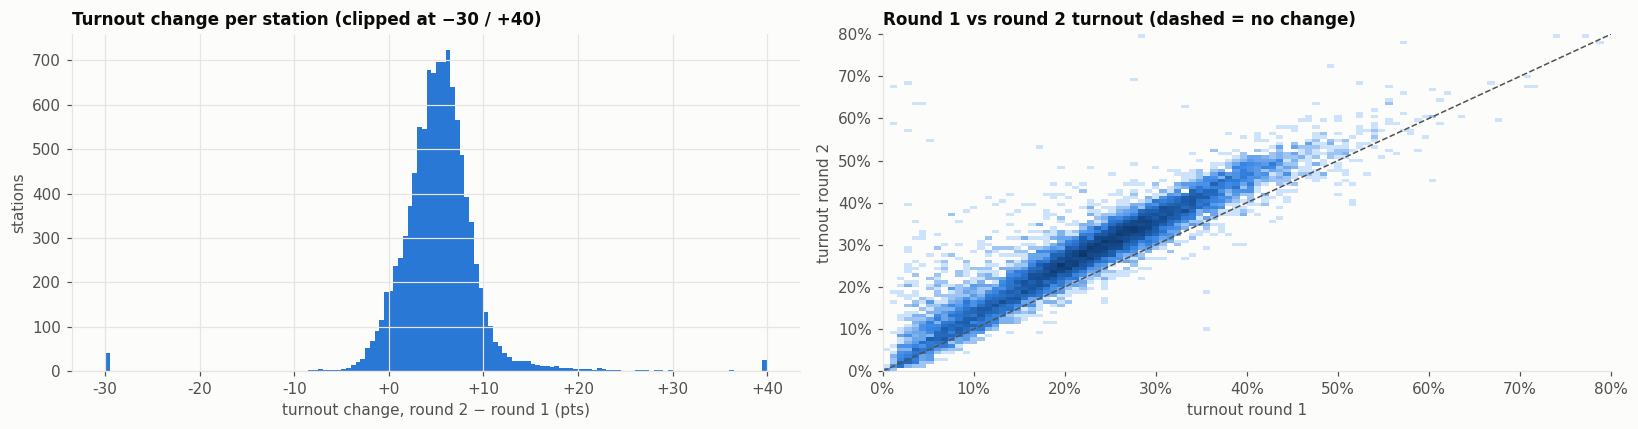

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
ax = axes[0]
ax.hist(X["dt"].clip(-0.3, 0.4), bins=np.arange(-0.3, 0.401, 0.005), color=BLUE, linewidth=0)
ax.set_xlabel("turnout change, round 2 − round 1 (pts)"); ax.set_ylabel("stations")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v*100:+.0f}"))
ax.set_title("Turnout change per station (clipped at −30 / +40)")
ax = axes[1]
ax.hist2d(X["t1"], X["t2"], bins=100, range=[[0, 0.8], [0, 0.8]], cmap=SEQ, norm=LogNorm(), cmin=1)
ax.plot([0, 0.8], [0, 0.8], color=INK2, lw=1, ls="--"); ax.grid(False)
ax.set_xlabel("turnout round 1"); ax.set_ylabel("turnout round 2"); ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_title("Round 1 vs round 2 turnout (dashed = no change)")
fig.tight_layout(); plt.show()

### Who got the new voters?
Within each municipality, we regress each candidate's round-2 votes per registered voter on the **change in turnout**, controlling
for round-1 turnout and the candidates' round-1 shares (so we compare stations with similar starting points). The slope is the share of
each *additional* runoff voter that went to the candidate. For calibration we also inject stuffing for Йотова into 5% of stations.

In [20]:
def new_voter_split(data, rng_seed=None, stuff_for=None):
    d = data.copy()
    if stuff_for is not None:      # calibration: add 10–40% of non-voters as ballots for one candidate in 5% of stations
        r = np.random.default_rng(rng_seed)
        idx = r.choice(len(d), int(0.05 * len(d)), replace=False); sub = d.iloc[idx]
        add = np.round((sub["reg2"] - sub["voted2"]) * r.uniform(0.1, 0.4, len(sub)))
        d.loc[sub.index, f"r2|{stuff_for}"] += add; d.loc[sub.index, "voted2"] += add; d.loc[sub.index, "valid2"] += add
        d["t2"] = d["voted2"] / d["reg2"]; d["dt"] = d["t2"] - d["t1"]
    controls = ["t1"] + [f"r1 share|{c}" for c in TOP]
    out = {}
    for c in TOP:
        y = d[f"r2|{c}"] / d["reg2"]
        Xm = d[["dt"] + controls]
        Xd = Xm - Xm.groupby(d["municipality"]).transform("mean")
        yd = y - y.groupby(d["municipality"]).transform("mean")
        beta = np.linalg.lstsq(Xd.to_numpy(), yd.to_numpy(), rcond=None)[0]
        out[short(c)] = beta[0]
    return pd.Series(out)

overall2 = pd.Series({short(c): X[f"r2|{c}"].sum() / X["valid2"].sum() for c in TOP})
split = pd.DataFrame({"round-2 share overall": overall2,
                      "share of extra voters (real)": new_voter_split(X),
                      f"… with injected stuffing for {short(TOP[0])}": new_voter_split(X, 1, stuff_for=TOP[0])})
split.style.format("{:.1%}")

,round-2 share overall,share of extra voters (real),… with injected stuffing for Илияна Йотова
Илияна Йотова,58.4%,59.3%,73.3%
Андрей Гюров,38.7%,37.1%,24.2%


### Stations with a turnout surge
Stations whose turnout rose **more than 15 pts above their municipality's typical change**. For each one we show the round-2 winner's
share and whether the **voter list itself changed** (a corrected list makes turnout jump on paper without anyone extra voting).

In [21]:
surge = X[X["dt_rel"] > 0.15].copy()
surge["winner r2"] = surge[[f"r2 share|{c}" for c in TOP]].idxmax(axis=1).str.replace("r2 share|", "", regex=False).map(short)
surge["winner share r2"] = surge[[f"r2 share|{c}" for c in TOP]].max(axis=1)
surge[f"{short(TOP[0])} r2 share"] = surge[f"r2 share|{TOP[0]}"]
surge[f"municipality {short(TOP[0])} share"] = surge["municipality"].map(
    X.groupby("municipality").apply(lambda g: g[f"r2|{TOP[0]}"].sum() / g["valid2"].sum(), include_groups=False))
surge["list_fix"] = surge["list change"].abs() > 0.3
print(f"{len(surge)} surge stations ({surge['list_fix'].sum()} of them with a voter list that changed by more than 30%)")
cols = ["place", "address", "reg1", "reg2", "voted1", "voted2", "t1", "t2", "dt_rel", f"{short(TOP[0])} r2 share",
        f"municipality {short(TOP[0])} share", "list_fix"]
surge[cols].sort_values("dt_rel", ascending=False).style.format({
    "t1": "{:.0%}", "t2": "{:.0%}", "dt_rel": "{:+.0%}", f"{short(TOP[0])} r2 share": "{:.0%}", f"municipality {short(TOP[0])} share": "{:.0%}"})

57 surge stations (19 of them with a voter list that changed by more than 30%)


,place,address,reg1,reg2,voted1,voted2,t1,t2,dt_rel,Илияна Йотова r2 share,municipality Илияна Йотова share,list_fix
section,,,,,,,,,,,,
021800037,с.Скалак,"С.СКАЛАК, ОУ Йордан Йовков",615,107,34,100,6%,93%,+87%,50%,48%,True
011100034,с.Брезница,"С.БРЕЗНИЦА, ОСНОВНО УЧИЛИЩЕ СВ.СВ.КИРИЛ И МЕТОДИЙ , УЛ. ЧАРКА №23",846,175,81,175,10%,100%,+84%,71%,54%,True
013300088,с.Габрене,"С.ГАБРЕНЕ, КЛУБ НА ПЕНСИОНЕРА",783,129,102,127,13%,98%,+78%,81%,71%,True
301100009,с.Живково,"С.ЖИВКОВО, Зала ул. Тополите №22",879,168,153,162,17%,96%,+77%,9%,17%,True
062700033,с.Моравица,"С.МОРАВИЦА, ОУ Васил Кънчов , ул. Емил Марков №3",531,116,86,113,16%,97%,+76%,69%,72%,True
171700026,с.Крислово,"С.КРИСЛОВО, Младежки дом, ул. Георги Димитров №19",494,125,91,124,18%,99%,+76%,73%,67%,True
264300017,с.Гара Лакатник,"С.ЛАКАТНИК(ГАРА ЛАКАТНИК), НАРОДНО ЧИТАЛИЩЕ ИСКЪРСКИ ПРОЛОМ-1934 ,площад Центъра №2",413,116,75,110,18%,95%,+71%,65%,60%,True
223100039,гр.Смолян,"ГР.СМОЛЯН, ПГИ Карл Маркс (главен вход вляво), ул. Елица №001",516,167,135,167,26%,100%,+70%,58%,65%,True
050600007,с.Гъмзово,"С.ГЪМЗОВО, Клуб на пенсионера",453,126,113,122,25%,97%,+68%,66%,57%,True


In [22]:
ns = surge[~surge["list_fix"]]
print(f"Real surges (voter list stable): {len(ns)} stations, {int(ns['voted2'].sum() - ns['voted1'].sum()):,} extra voters in total")
if len(ns):
    print(f"  {short(TOP[0])}'s share in them: {ns[f'r2|{TOP[0]}'].sum() / ns['valid2'].sum():.1%}  vs  "
          f"{(ns[f'municipality {short(TOP[0])} share'] * ns['valid2']).sum() / ns['valid2'].sum():.1%} in their municipalities")

Real surges (voter list stable): 38 stations, 3,674 extra voters in total
  Илияна Йотова's share in them: 40.9%  vs  52.5% in their municipalities


### Where did round-1 abstainers come out?
Stations grouped by their **round-1 turnout**. For each group: how much the number of valid votes grew, and how the **net growth**
split between the candidates. Net growth includes both new voters and voters of eliminated round-1 candidates, so it is not a pure
“new voter” measure. Only stations with a stable voter list (change < 30%) are used.

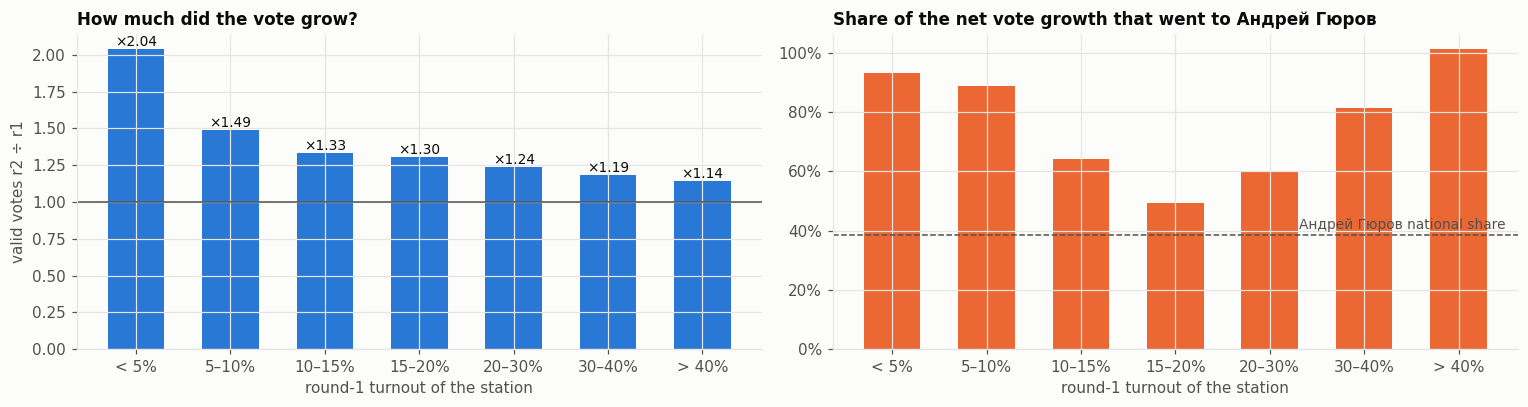

,stations,votes_r1,votes_r2,growth ×,Андрей Гюров share r2,Андрей Гюров share of net growth
round-1 turnout,,,,,,
< 5%,452,11799,24045,2.04,56%,93%
5–10%,945,49108,73208,1.49,41%,89%
10–15%,1041,78936,105287,1.33,30%,64%
15–20%,1645,174977,228035,1.30,28%,49%
20–30%,4120,618323,765667,1.24,35%,60%
30–40%,1801,359919,426745,1.19,48%,81%
> 40%,493,88775,101140,1.14,54%,101%


In [23]:
G_, Y_ = TOP[1], TOP[0]
Z = pd.DataFrame({"t1": r1.loc[common, "turnout"], "v1": r1.loc[common, "valid"], "v2": clean.loc[common, "valid"],
                  "G1": votes1.loc[common, G_], "Y1": votes1.loc[common, Y_], "G2": clean.loc[common, G_], "Y2": clean.loc[common, Y_],
                  "region": clean.loc[common, "admin_name"], "municipality": clean.loc[common, "municipality"],
                  "place": clean.loc[common, "place"], "reg1": r1.loc[common, "registered"], "reg2": clean.loc[common, "registered"]})
Z = Z[(Z["reg1"] >= 100) & ((Z["reg2"] / Z["reg1"] - 1).abs() < 0.3)]
Z["round-1 turnout"] = pd.cut(Z["t1"], [0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 1.01],
                              labels=["< 5%", "5–10%", "10–15%", "15–20%", "20–30%", "30–40%", "> 40%"])
g = Z.groupby("round-1 turnout", observed=True).agg(stations=("v1", "size"), votes_r1=("v1", "sum"), votes_r2=("v2", "sum"),
                                                     G1=("G1", "sum"), G2=("G2", "sum"), Y1=("Y1", "sum"), Y2=("Y2", "sum"))
g["growth ×"] = g["votes_r2"] / g["votes_r1"]
g[f"{short(G_)} share of net growth"] = (g["G2"] - g["G1"]) / (g["votes_r2"] - g["votes_r1"])
g[f"{short(G_)} share r2"] = g["G2"] / g["votes_r2"]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
x = np.arange(len(g))
axes[0].bar(x, g["growth ×"], width=0.6, color=BLUE)
axes[0].set_xticks(x, g.index); axes[0].set_xlabel("round-1 turnout of the station"); axes[0].set_ylabel("valid votes r2 ÷ r1")
axes[0].set_title("How much did the vote grow?"); axes[0].axhline(1, color=INK2, lw=1)
for xi, v in zip(x, g["growth ×"]): axes[0].text(xi, v, f"×{v:.2f}", ha="center", va="bottom", fontsize=9, color=INK)
axes[1].bar(x, g[f"{short(G_)} share of net growth"], width=0.6, color=ORANGE)
axes[1].axhline(clean[G_].sum() / clean["valid"].sum(), color=INK2, lw=1, ls="--")
axes[1].text(len(g) - 0.5, clean[G_].sum() / clean["valid"].sum() + 0.02, f"{short(G_)} national share", ha="right", fontsize=9, color=INK2)
axes[1].set_xticks(x, g.index); axes[1].set_xlabel("round-1 turnout of the station"); axes[1].yaxis.set_major_formatter(pct)
axes[1].set_title(f"Share of the net vote growth that went to {short(G_)}")
fig.tight_layout(); plt.show()
g[["stations", "votes_r1", "votes_r2", "growth ×", f"{short(G_)} share r2", f"{short(G_)} share of net growth"]].style.format(
    {"growth ×": "{:.2f}", f"{short(G_)} share r2": "{:.0%}", f"{short(G_)} share of net growth": "{:.0%}"})

In [24]:
low = Z[Z["t1"] < 0.10]
extra = low["v2"].sum() - low["v1"].sum()
net = (low["G2"] - low["G1"]).sum() - (low["Y2"] - low["Y1"]).sum()
margin = clean[Y_].sum() - clean[G_].sum()
print(f"Stations with round-1 turnout < 10%: {len(low)}; extra valid votes in round 2: {extra:,}; "
      f"net gain of {short(G_)} over {short(Y_)} there: {net:,}  (national margin in these stations: {margin:,})")
jump = low[(low["v2"] >= 4 * low["v1"].clip(lower=1)) & (low["v2"] >= 50)]
print(f"…of which {len(jump)} stations multiplied their vote ≥ 4×; {short(G_)} got {jump['G2'].sum() / jump['v2'].sum():.0%} there.")
jump.groupby("municipality").agg(stations=("v1", "size"), example=("place", "first"), region=("region", "first"),
                                 votes_r1=("v1", "sum"), votes_r2=("v2", "sum"),
                                 **{f"{short(G_)} share r2": ("G2", "sum")}).assign(
    **{f"{short(G_)} share r2": lambda t: t[f"{short(G_)} share r2"] / t["votes_r2"]}).sort_values("votes_r2", ascending=False) \
    .style.format({f"{short(G_)} share r2": "{:.0%}"})

Stations with round-1 turnout < 10%: 1392; extra valid votes in round 2: 36,308; net gain of Андрей Гюров over Илияна Йотова there: 4,874  (national margin in these stations: 342,857)
…of which 69 stations multiplied their vote ≥ 4×; Андрей Гюров got 78% there.


,stations,example,region,votes_r1,votes_r2,Андрей Гюров share r2
municipality,,,,,,
0102,11,с.Дагоново,01. БЛАГОЕВГРАД,230,2236,80%
0153,6,гр.Якоруда,01. БЛАГОЕВГРАД,147,1223,76%
0916,12,с.Седловина,09. КЪРДЖАЛИ,161,1082,85%
3018,4,с.Браничево,30. ШУМЕН,127,804,81%
3010,4,с.Божурово,30. ШУМЕН,132,644,74%
0921,5,с.Врело,09. КЪРДЖАЛИ,75,360,83%
0915,5,с.Бараци,09. КЪРДЖАЛИ,61,357,89%
2930,3,с.Бял кладенец,29. ХАСКОВО,57,279,81%
2934,1,с.Козлец,29. ХАСКОВО,23,203,84%


### Round-1 bloc stations: did the bloc move?
The stations where Василев won small low-turnout blocs in round 1 (round-1 turnout < 12%, Василев > 50%).

In [25]:
V = "17 Радостин Василев"
blocs = r1[(r1["turnout"] < 0.12) & (votes1[V] / r1["valid"] > 0.5) & (r1["registered"] >= 100)].index.intersection(clean.index)
B = pd.DataFrame({
    "place": clean.loc[blocs, "place"],
    "round-1 voted": r1.loc[blocs, "voted"], "Василев votes r1": votes1.loc[blocs, V],
    "round-2 voted": clean.loc[blocs, "voted"],
    f"{short(TOP[0])} r2 share": clean.loc[blocs, f"share|{TOP[0]}"],
    f"municipality {short(TOP[0])} share": clean.loc[blocs, "municipality"].map(
        clean.groupby("municipality").apply(lambda g: g[TOP[0]].sum() / g["valid"].sum(), include_groups=False)),
})
fell = (B["round-2 voted"] < B["round-1 voted"]).mean()
print(f"{len(B)} round-1 bloc stations. Round-2 turnout lower than round 1 in {fell:.0%} of them "
      f"(nationally turnout rose in {(X['dt'] > 0).mean():.0%} of stations).")
w = clean.loc[blocs, "valid"]
print(f"{short(TOP[0])}'s runoff share in these stations: {(B[f'{short(TOP[0])} r2 share'] * w).sum() / w.sum():.1%}  vs  "
      f"{(B[f'municipality {short(TOP[0])} share'] * w).sum() / w.sum():.1%} in their municipalities")
print(f"stations where one runoff candidate got > 85%: {(clean.loc[blocs, [f'share|{c}' for c in TOP]].max(axis=1) > 0.85).sum()}")
B.sort_values("round-1 voted", ascending=False).style.format({f"{short(TOP[0])} r2 share": "{:.0%}", f"municipality {short(TOP[0])} share": "{:.0%}"})

55 round-1 bloc stations. Round-2 turnout lower than round 1 in 60% of them (nationally turnout rose in 94% of stations).
Илияна Йотова's runoff share in these stations: 60.1%  vs  68.0% in their municipalities
stations where one runoff candidate got > 85%: 4


,place,round-1 voted,Василев votes r1,round-2 voted,Илияна Йотова r2 share,municipality Илияна Йотова share
section,,,,,,
132100023,гр.Пещера,93,49,147,90%,72%
273100136,гр.Стара Загора,85,50,46,59%,63%
132900028,с.Семчиново,84,61,128,32%,65%
122900056,гр.Монтана,80,53,65,60%,70%
272200016,с.Зимница,77,47,50,64%,74%
132900002,гр.Септември,65,33,67,40%,65%
273100138,гр.Стара Загора,63,32,30,70%,63%
172500015,гр.Раковски,62,39,31,26%,68%
042200027,с.Върбовка,59,35,40,82%,73%


### Do the round-1 voter-list errors repeat?

In [26]:
def list_errors(d):
    bld = d.groupby("address")["voters_list"].transform(lambda s: (s.sum() - s) / max(len(s) - 1, 1))
    return d.index[(d["turnout"] >= 0.95) & (d["voters_list"] < 0.6 * bld) & (d.groupby("address")["voters_list"].transform("size") > 1)]

r1_reg = r1[~r1["abroad"] & (r1["mobile"] == 0) & (r1["ship"] == 0) & (r1["registered"] >= 100)]
e1, e2 = set(list_errors(r1_reg)), set(list_errors(base))
print(f"round-1 list errors: {len(e1)};  round-2 list errors: {len(e2)};  in both rounds: {len(e1 & e2)}")
rep_tab = pd.DataFrame({
    "list r1": r1.loc[sorted(e1), "voters_list"], "voted r1": r1.loc[sorted(e1), "voted"],
    "list r2": df["voters_list"].reindex(sorted(e1)), "voted r2": df["voted"].reindex(sorted(e1)),
    "error again in r2": [s in e2 for s in sorted(e1)],
})
rep_tab.head(45)

round-1 list errors: 39;  round-2 list errors: 42;  in both rounds: 12


,list r1,voted r1,list r2,voted r2,error again in r2
section,,,,,
020400071,159,165,568,199,False
020400108,122,122,641,155,False
020400145,126,129,616,150,False
020400220,97,97,611,139,False
030602134,269,296,747,339,False
040400052,225,232,292,296,True
050900058,97,104,102,109,True
050900079,124,124,761,165,False
061000037,113,118,435,142,False


## 12. Integer-percentage test (Kobak et al.)
When officials fabricate results to hit a target, the protocol numbers often produce **round percentages**, e.g. turnout
of exactly 60.0% or a candidate share of exactly 50.0%. In Russian elections this showed up as sharp spikes at integer
percentages.

Small stations hit integer percentages by chance (e.g. 50 of 100), so we compare with a **binomial re-sampling null**: each
station's count is re-drawn from Binomial(n, observed rate), which keeps every station's size and rate but removes any
deliberate targeting.

In [27]:
# 0% and 100% are excluded: they are trivially "integer" and dominated by tiny counts
def is_integer_pct(k, n):
    k, n = np.asarray(k, dtype=np.int64), np.asarray(n, dtype=np.int64)
    return (k > 0) & (k < n) & ((100 * k) % np.maximum(n, 1) == 0)

def is_round_pct(k, n):     # multiple of 5%
    k, n = np.asarray(k, dtype=np.int64), np.asarray(n, dtype=np.int64)
    return (k > 0) & (k < n) & ((20 * k) % np.maximum(n, 1) == 0)

tests = {"Turnout": (clean["voted"], clean["registered"])} | {f"Share {short(c)}": (clean[c], clean["valid"]) for c in TOP}
N_SIM = 200
rows = {}
for name, (k, n) in tests.items():
    k, n = k.to_numpy().astype(int), n.to_numpy().astype(int)
    p = np.clip(k / np.maximum(n, 1), 0, 1)
    obs_i, obs_r = is_integer_pct(k, n).sum(), is_round_pct(k, n).sum()
    sim_i, sim_r = [], []
    for _ in range(N_SIM):
        ks = rng.binomial(n, p)
        sim_i.append(is_integer_pct(ks, n).sum()); sim_r.append(is_round_pct(ks, n).sum())
    sim_i, sim_r = np.array(sim_i), np.array(sim_r)
    rows[name] = {"integer % — observed": obs_i, "integer % — null (5–95%)": f"{np.percentile(sim_i, 5):.0f} – {np.percentile(sim_i, 95):.0f}",
                  "integer % — p": (sim_i >= obs_i).mean(),
                  "multiple of 5% — observed": obs_r, "multiple of 5% — null (5–95%)": f"{np.percentile(sim_r, 5):.0f} – {np.percentile(sim_r, 95):.0f}",
                  "multiple of 5% — p": (sim_r >= obs_r).mean()}
kobak = pd.DataFrame(rows).T
kobak

,integer % — observed,integer % — null (5–95%),integer % — p,multiple of 5% — observed,multiple of 5% — null (5–95%),multiple of 5% — p
Turnout,100,88 – 120,0.665,64,52 – 78,0.55
Share Илияна Йотова,464,445 – 495,0.66,319,294 – 341,0.495
Share Андрей Гюров,487,439 – 495,0.115,328,289 – 341,0.145


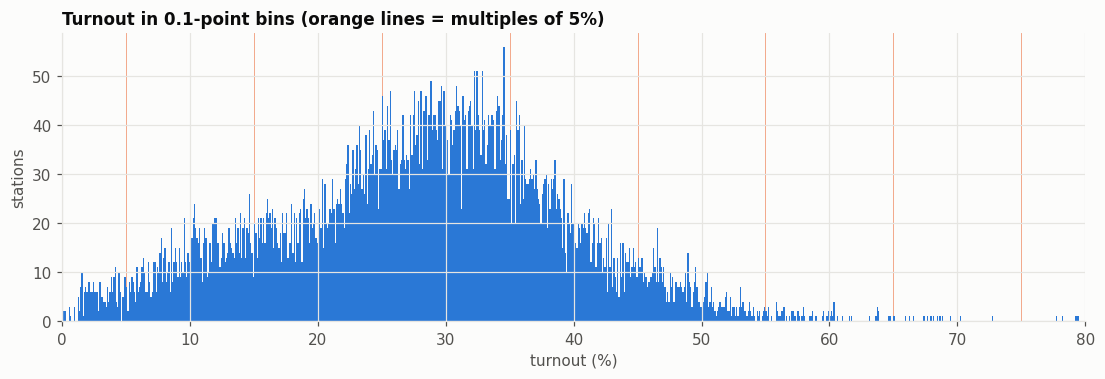

In [28]:
# Visual: fine-grained turnout histogram (0.1-pt bins). Spikes at integer % would appear as regular needles.
fig, ax = plt.subplots(figsize=(12, 3.4))
t = clean["turnout"] * 100
ax.hist(t, bins=np.arange(0, 100.05, 0.1), color=BLUE, linewidth=0)
for k in range(5, 100, 5):
    ax.axvline(k, color=ORANGE, lw=0.6, alpha=0.6, zorder=0)
ax.set_xlim(0, 80); ax.set_xlabel("turnout (%)"); ax.set_ylabel("stations")
ax.set_title("Turnout in 0.1-point bins (orange lines = multiples of 5%)")
plt.show()

## 13. Conclusions

| Check | Finding | Fraud signal? |
|---|---|---|
| **100% turnout spike** | 42 stations with a voter list 3–5× smaller than their same-building neighbours. **Only 12 of them repeat from round 1**: committees make this protocol error afresh each round. | **No.** A data-quality issue, worth reporting to the CIK |
| **Fingerprint shape** | Compact blobs; no comet tail toward high turnout + high share | **No** |
| **Extreme corner** (turnout > 70%, share > 85%) | 3 stations. Живково (Гюров 90%) and Алфатар (Йотова 93%) are voter-list errors without a neighbour to compare with (list fell from 879→168 and 491→174 between rounds). с. Градина (Йотова 88%, 70% turnout, 141 voters) was also in round 1's corner. Injecting extreme fraud in 1% of stations would put ~108 there. | **No large-scale extreme fraud.** Градина is worth a look. |
| **Turnout–share slopes** | Гюров's share rises with turnout, driven by Sofia and the cities. Extra voters split exactly like everyone else (ratio 0.96–1.06). | **No** |
| **Integer percentages** | All inside the null range | **No** |
| **Turnout change r1 → r2** | +5.3 pts in the median station, remarkably uniform across all 31 regions. The additional runoff voters split 59% / 37%, the same as the overall result. Injected stuffing for Йотова would push her share of new voters to 73%. | **No stuffing in the runoff** |
| **Turnout surges** | 57 stations surged > 15 pts above their municipality; 19 are voter-list changes. The 38 real surges add only 3,674 voters and **favour Гюров** (Йотова 41% vs 53% in their municipalities). | **No** (and not in favour of the winner) |
| **Abstainer mobilisation** | Where round-1 turnout was < 10%, the vote grew 1.5–2× and **~90% of the net growth went to Гюров**. 69 stations multiplied their vote ≥ 4×, 78% for Гюров, clustered in Кърджали, Белица and Якоруда (Благоевград), Шумен and Хасково. | **A coordinated regional mobilisation for Гюров.** This is typical of an organised endorsement; the data can't tell a legitimate one from a controlled one. Net effect ≈ +4,900 votes. |
| **Round-1 Василев blocs** | They did **not** move as a block: turnout fell in 60% of them (it rose in 94% of stations nationally), and Йотова got 60% vs 68% in their municipalities. But 4 stations (Любимец ×2, Пещера, Вършец) went > 85% Йотова with rising turnout. | **Mostly no.** A handful look like a transferred bloc. |

### Bottom line
**There is no statistical sign of ballot stuffing or fabricated turnout in the runoff.** Turnout rose evenly everywhere, and the
new voters split just like the old ones. The one clearly organised pattern is a **mobilisation in favour of the losing candidate**,
Гюров, in a few dozen villages in regions that largely abstained in round 1. Bloc-like behaviour also reappears in a handful of
round-1 Василев stations, now for Йотова.

None of this comes close to mattering for the outcome. **Йотова won by 343,601 votes**; every pattern flagged here involves at most a few
thousand.

### Limits
Same as round 1: this method sees fraud that **raises turnout**. Vote buying among people who would vote anyway, or pressure on
dependent voters, leaves little trace. Abroad, mobile and special sections are excluded.